<a href="https://colab.research.google.com/github/GMP-19/Real-time-sensor-anomaly-detection/blob/main/Real_Time_Sensor_Anomaly_Detection_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Real-Time Sensor Anomaly Detection and Monitoring System Using Isolation Forest

## 1. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

## 2. Load Dataset

In [ ]:
import pandas as pd

# Column names
columns = [
    "unit_id", "cycle",
    "setting_1", "setting_2", "setting_3"
]

# Add 21 sensor names
columns += [f"sensor_{i}" for i in range(1, 22)]

# Read dataset
df = pd.read_csv(
    "train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

# Display first 5 rows
df.head()

,unit_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 3. Understand the Dataset

In [ ]:
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))
print("Number of engines:", df["unit_id"].nunique())

Number of rows: 20631
Number of columns: 26
Number of engines: 100


## 4. Sensor Statistics and Data Cleaning

In [ ]:
sensor_cols = [f"sensor_{i}" for i in range(1, 22)]

stats = pd.DataFrame({
    "Mean": df[sensor_cols].mean(),
    "Std Dev": df[sensor_cols].std(),
    "Min": df[sensor_cols].min(),
    "Max": df[sensor_cols].max(),
    "Unique Values": df[sensor_cols].nunique()
})

stats.round(4)

,Mean,Std Dev,Min,Max,Unique Values
sensor_1,518.6700,0.0000,518.6700,518.6700,1
sensor_2,642.6809,0.5001,641.2100,644.5300,310
sensor_3,1590.5231,6.1311,1571.0400,1616.9100,3012
sensor_4,1408.9338,9.0006,1382.2500,1441.4900,4051
sensor_5,14.6200,0.0000,14.6200,14.6200,1
sensor_6,21.6098,0.0014,21.6000,21.6100,2
sensor_7,553.3677,0.8851,549.8500,556.0600,513
sensor_8,2388.0967,0.0710,2387.9000,2388.5600,53
sensor_9,9065.2429,22.0829,9021.7300,9244.5900,6403
sensor_10,1.3000,0.0000,1.3000,1.3000,1


## 4.1 Remove Constant Sensors

In [ ]:
constant_sensors = [
    "sensor_1",
    "sensor_5",
    "sensor_10",
    "sensor_16",
    "sensor_18",
    "sensor_19"
]

df_clean = df.drop(columns=constant_sensors)

print("Original columns:", df.shape[1])
print("Columns after removing constant sensors:", df_clean.shape[1])

print("\nRemaining sensors:")
print([col for col in df_clean.columns if "sensor" in col])

Original columns: 26
Columns after removing constant sensors: 20

Remaining sensors:
['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


## 4.2 Sensor Behavior Visualization

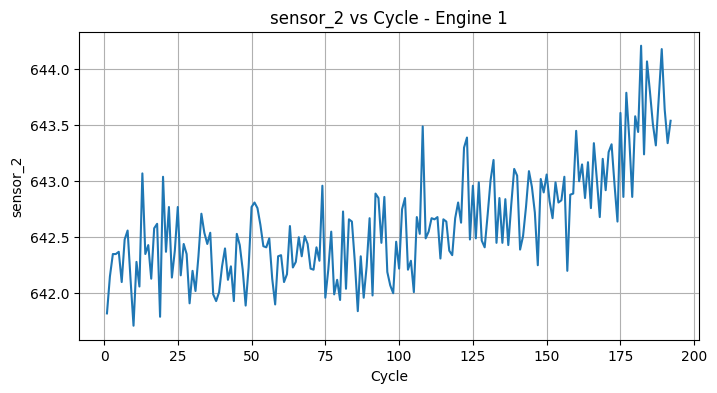

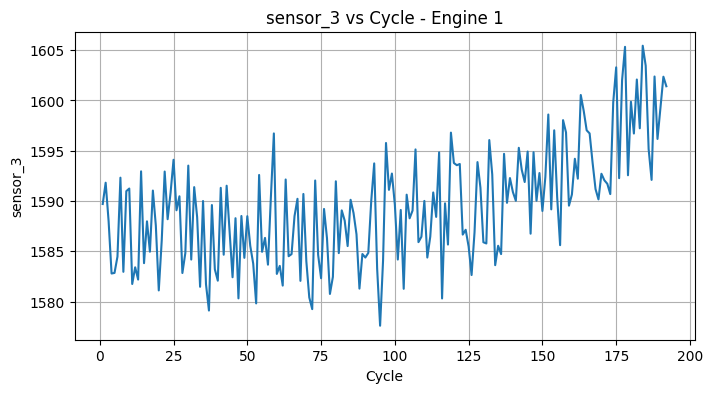

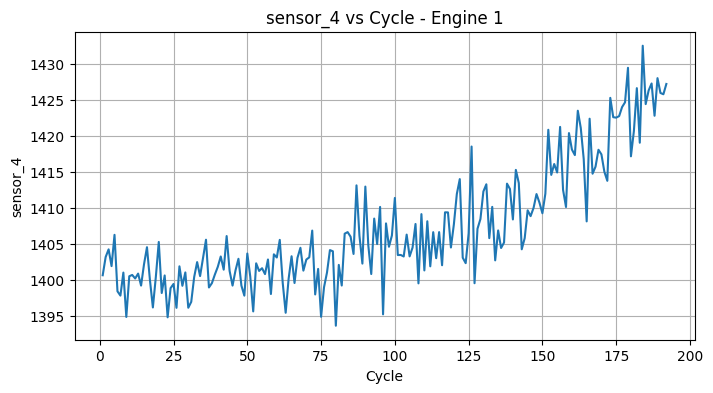

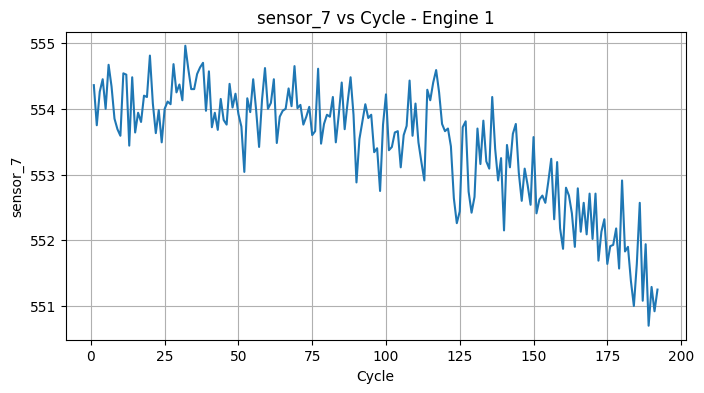

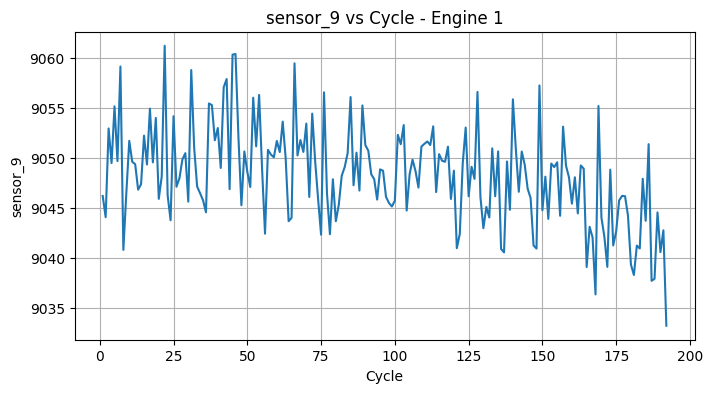

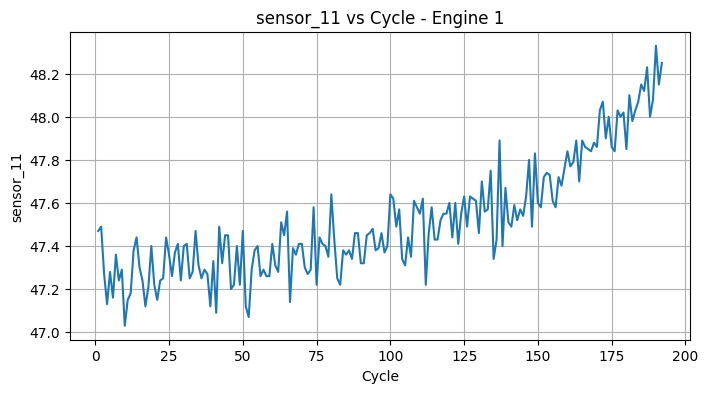

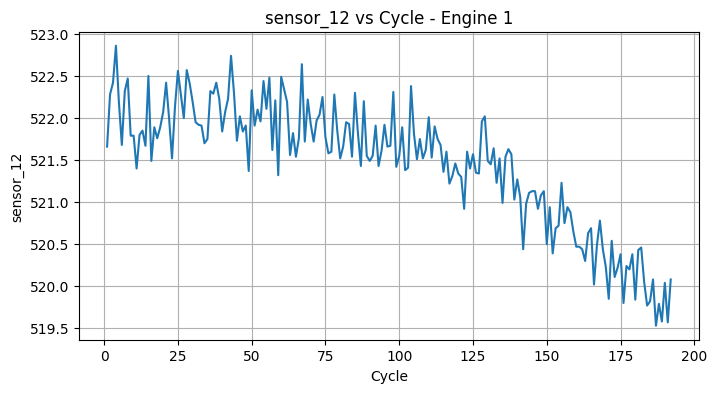

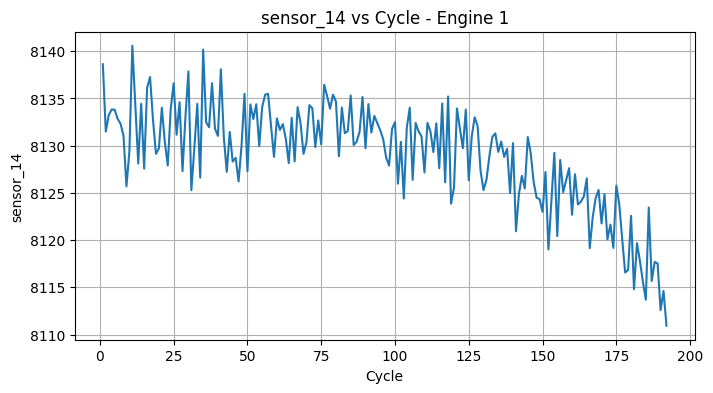

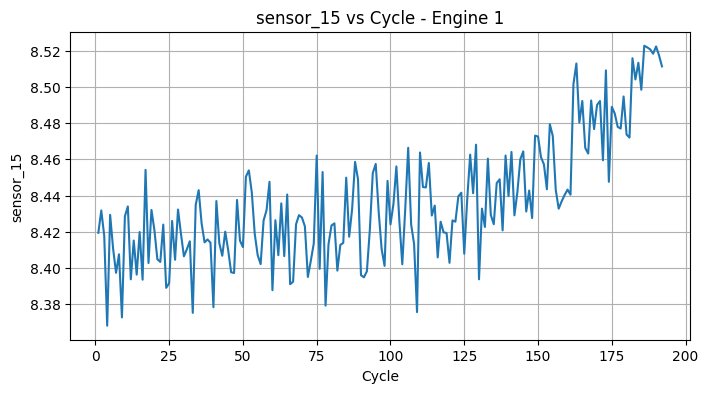

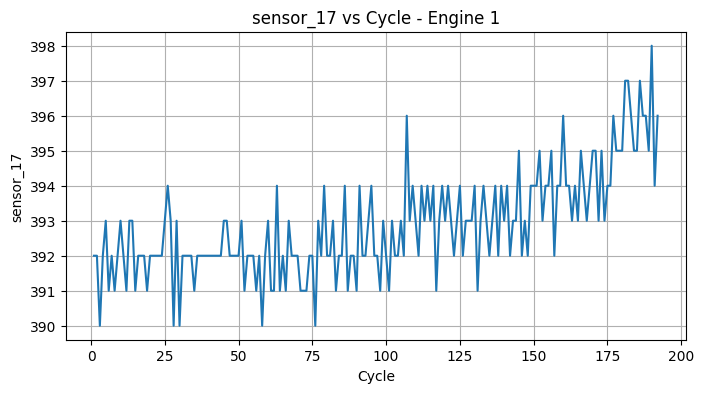

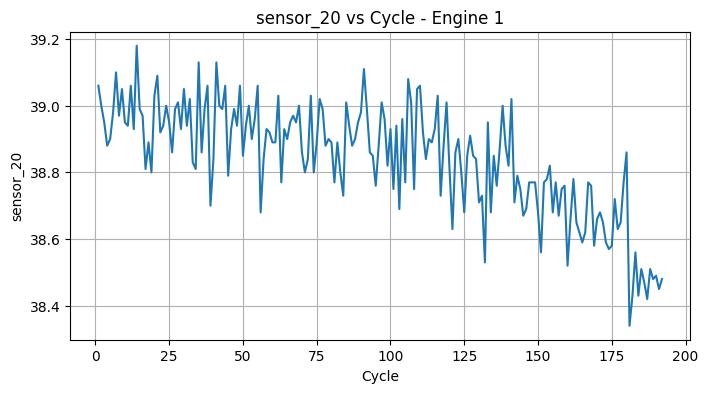

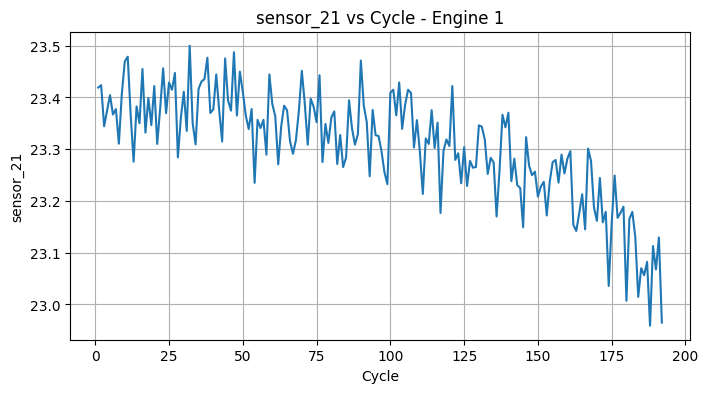

In [ ]:
import matplotlib.pyplot as plt

# Sensors that have variation
selected_sensors = [
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_7",
    "sensor_9",
    "sensor_11",
    "sensor_12",
    "sensor_14",
    "sensor_15",
    "sensor_17",
    "sensor_20",
    "sensor_21"
]

# Select one engine
engine_1 = df[df["unit_id"] == 1]

# Plot each sensor against engine cycle
for sensor in selected_sensors:
    plt.figure(figsize=(8, 4))
    plt.plot(engine_1["cycle"], engine_1[sensor])
    plt.xlabel("Cycle")
    plt.ylabel(sensor)
    plt.title(f"{sensor} vs Cycle - Engine 1")
    plt.grid(True)
    plt.show()

## 5. Feature Selection and Scaling

In [ ]:
# Get remaining sensor columns
sensor_features = [
    col for col in df_clean.columns
    if col.startswith("sensor_")
]

print("Number of sensors:", len(sensor_features))
print(sensor_features)

Number of sensors: 15
['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


## 5.1 Standardize Sensor Features

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X = scaler.fit_transform(df_clean[sensor_features])

print("Shape of X:", X.shape)

Shape of X: (20631, 15)


## 6. Isolation Forest Model

In [ ]:
from sklearn.ensemble import IsolationForest

model = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=42
)

model.fit(X)

print("Isolation Forest model trained successfully.")

Isolation Forest model trained successfully.


## 7. Anomaly Detection

In [ ]:
predictions = model.predict(X)

print(predictions[:20])

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


## 7.1 Count Normal and Anomalous Observations

In [ ]:
import numpy as np

print("Normal observations:", np.sum(predictions == 1))
print("Anomalous observations:", np.sum(predictions == -1))

Normal observations: 19599
Anomalous observations: 1032


## 7.2 Add Anomaly Labels

In [ ]:
df_clean["anomaly"] = predictions

## 7.3 Extract Anomalous Observations

In [ ]:
anomalies = df_clean[df_clean["anomaly"] == -1]

print("Number of anomalies:", len(anomalies))
anomalies.head()

Number of anomalies: 1032


,unit_id,cycle,setting_1,setting_2,setting_3,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,...,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21,anomaly
183,1,184,0.0004,0.0003,100.0,644.07,1605.44,1432.52,21.61,551.00,...,9047.91,48.07,519.77,2388.28,8115.61,8.5133,395,38.43,23.0146,-1
184,1,185,0.0008,0.0001,100.0,643.80,1603.46,1424.40,21.61,551.64,...,9043.71,48.15,519.82,2388.27,8113.69,8.4984,395,38.51,23.0700,-1
186,1,187,-0.0047,-0.0000,100.0,643.32,1592.10,1427.27,21.61,551.08,...,9037.71,48.23,519.53,2388.28,8115.67,8.5218,396,38.42,23.0822,-1
187,1,188,-0.0067,0.0003,100.0,643.75,1602.38,1422.78,21.61,551.94,...,9037.91,48.00,519.79,2388.23,8117.69,8.5207,396,38.51,22.9588,-1
188,1,189,-0.0006,0.0002,100.0,644.18,1596.17,1428.01,21.61,550.70,...,9044.55,48.08,519.58,2388.33,8117.51,8.5183,395,38.48,23.1127,-1


## 8. View Detected Anomalies

In [ ]:
print(anomalies[["unit_id", "cycle", "anomaly"]].head(20))

     unit_id  cycle  anomaly
183        1    184       -1
184        1    185       -1
186        1    187       -1
187        1    188       -1
188        1    189       -1
189        1    190       -1
190        1    191       -1
191        1    192       -1
192        2      1       -1
194        2      3       -1
196        2      5       -1
197        2      6       -1
200        2      9       -1
201        2     10       -1
217        2     26       -1
233        2     42       -1
243        2     52       -1
246        2     55       -1
266        2     75       -1
272        2     81       -1


## 8.1 Anomalies by Engine

In [ ]:
anomaly_by_engine = anomalies["unit_id"].value_counts()

print(anomaly_by_engine)

unit_id
5     25
2     23
75    22
95    21
83    20
      ..
20     4
70     4
85     4
93     4
98     3
Name: count, Length: 100, dtype: int64


## 8.2 Anomaly Count Visualization

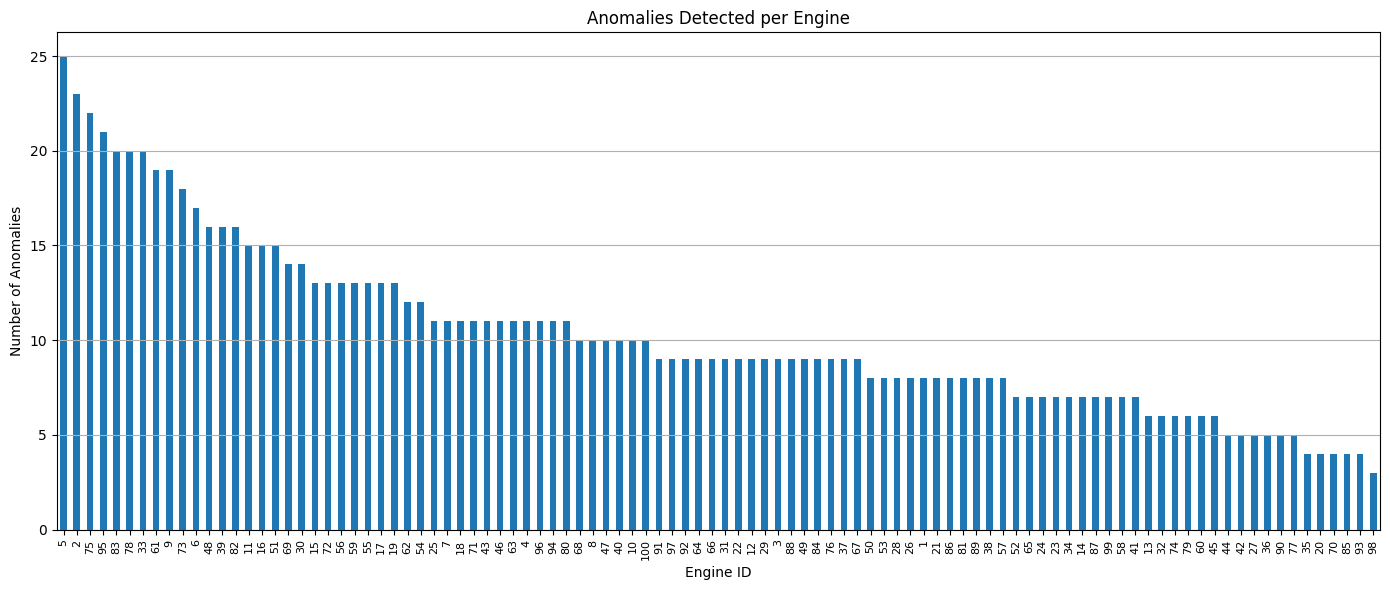

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

anomaly_by_engine.plot(kind="bar")

plt.xlabel("Engine ID")
plt.ylabel("Number of Anomalies")
plt.title("Anomalies Detected per Engine")

plt.xticks(rotation=90, fontsize=8)

plt.grid(axis="y")
plt.tight_layout()

plt.show()

## 8.3 Identify Engine with Most Anomalies

In [ ]:
top_engine = anomaly_by_engine.idxmax()
top_count = anomaly_by_engine.max()

print("Engine with most anomalies:", top_engine)
print("Number of anomalies:", top_count)

Engine with most anomalies: 5
Number of anomalies: 25


## 9. Sensor Behavior of Selected Engine

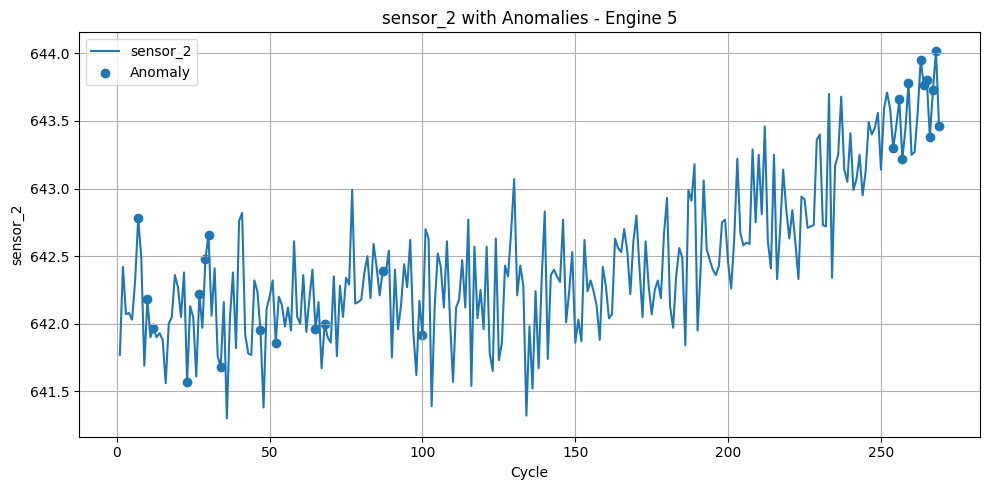

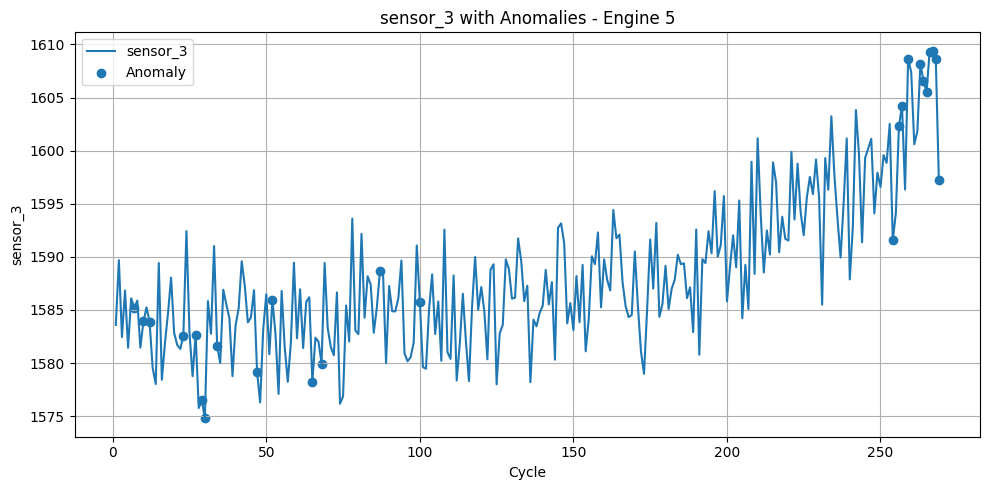

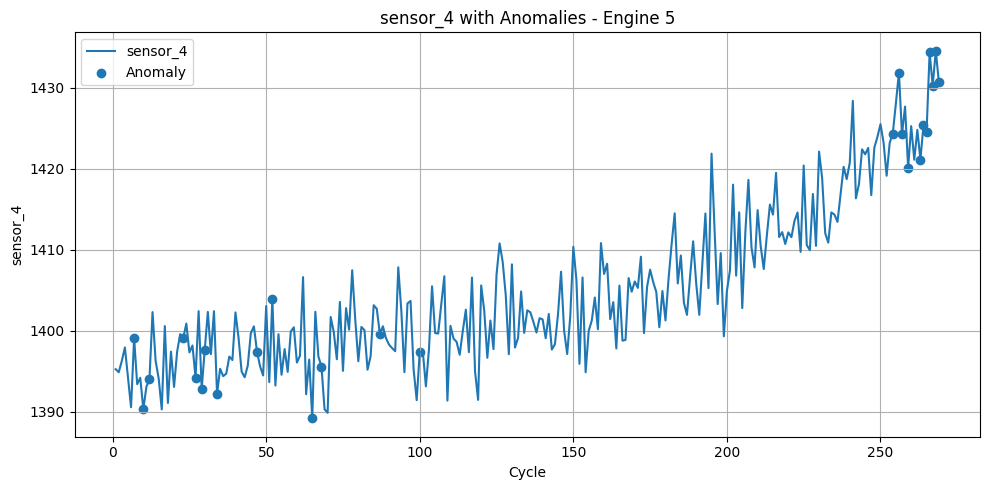

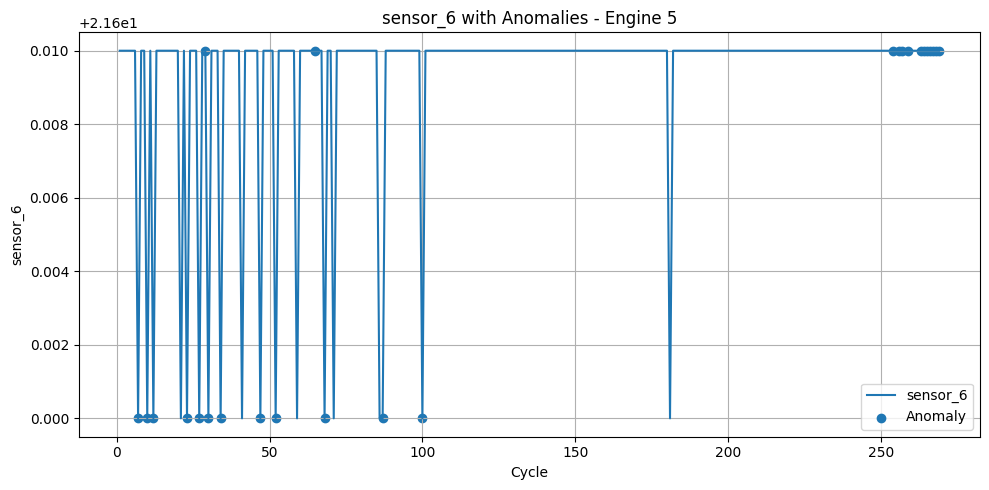

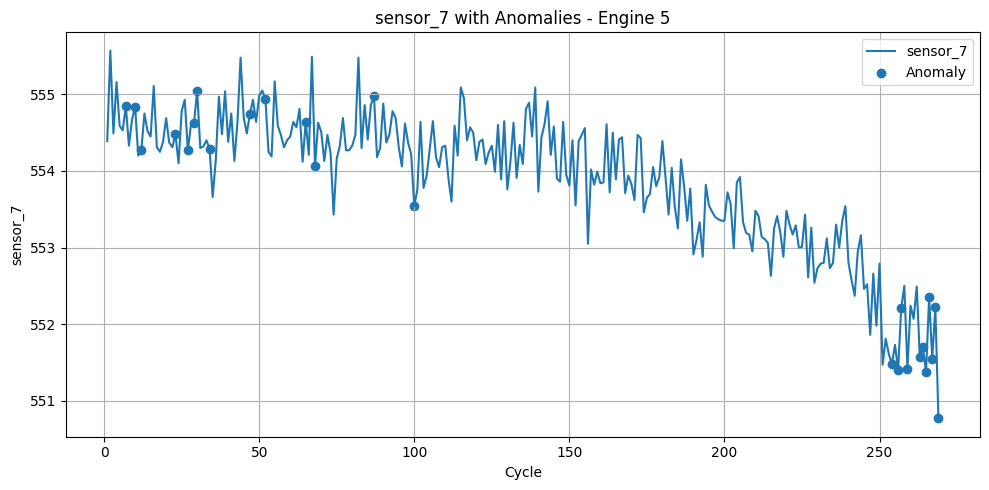

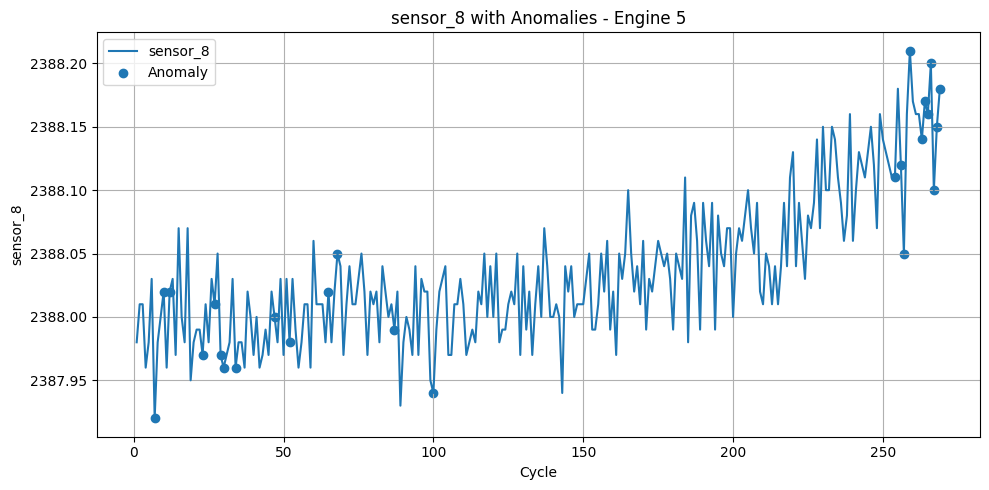

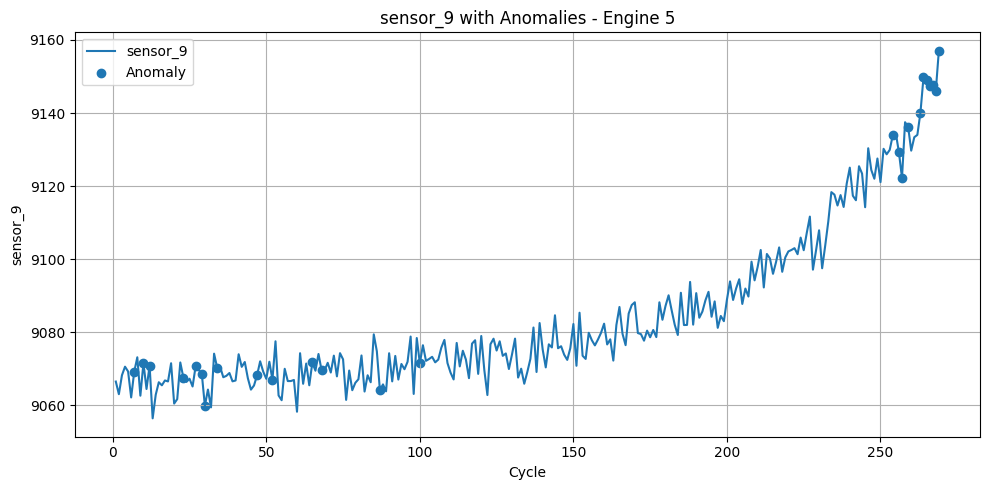

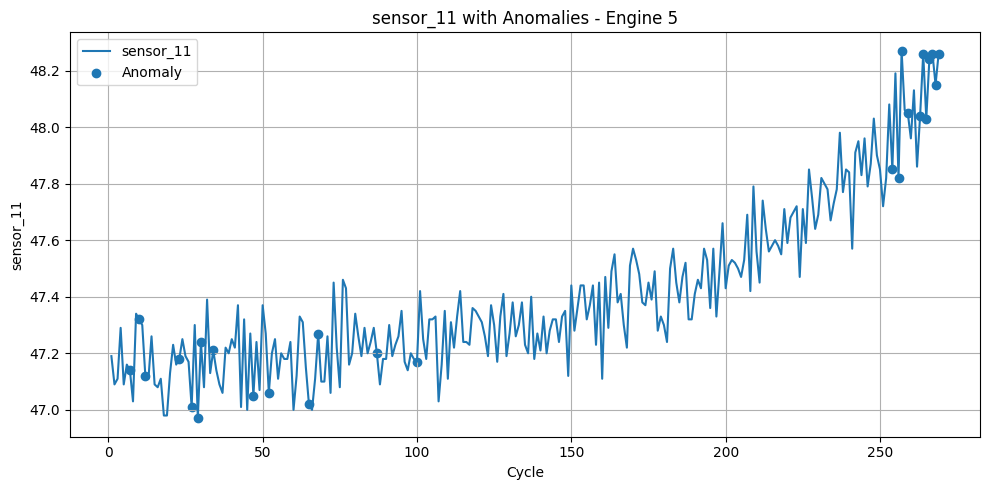

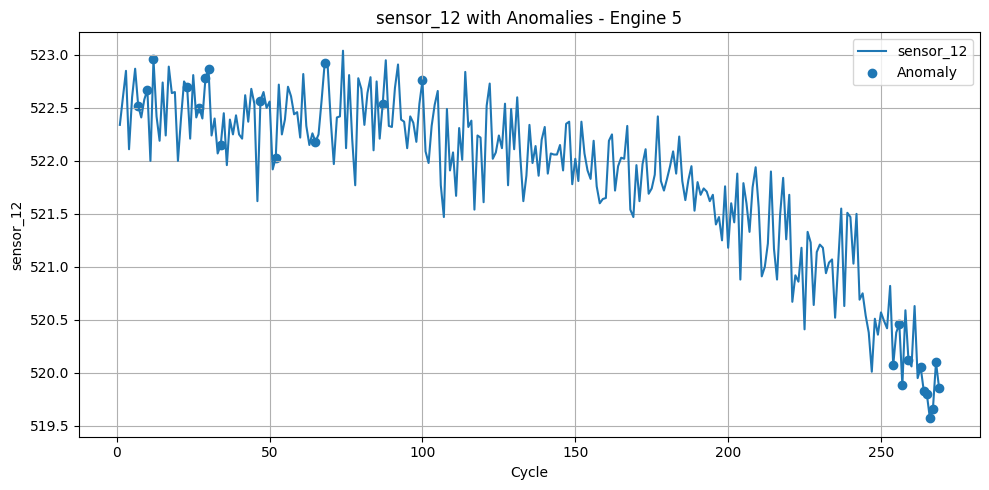

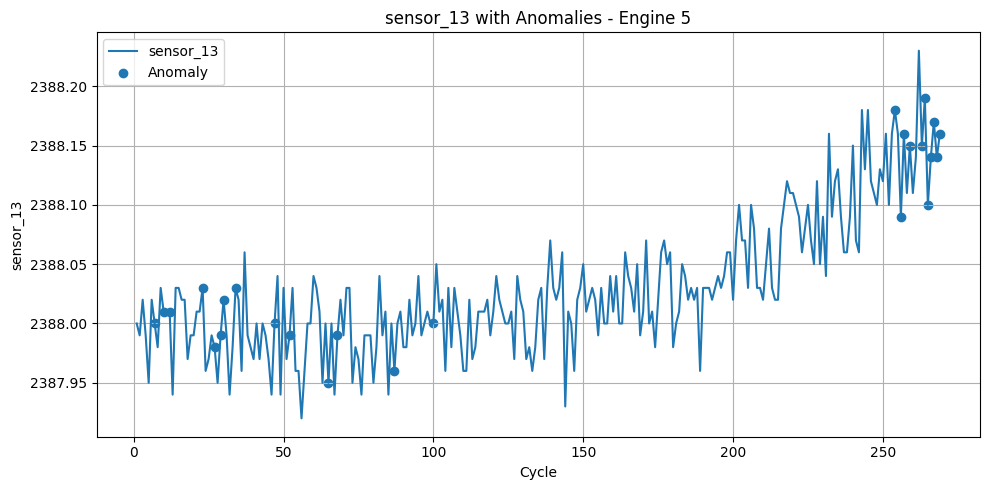

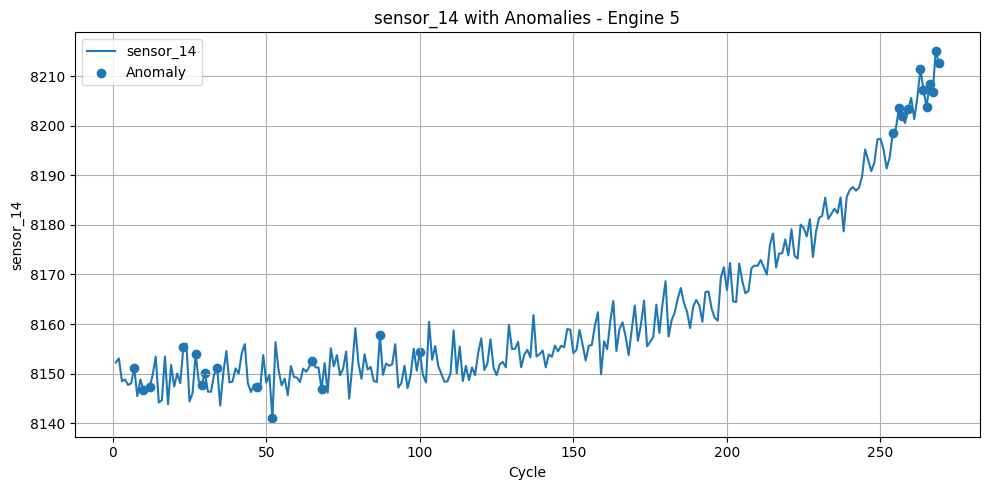

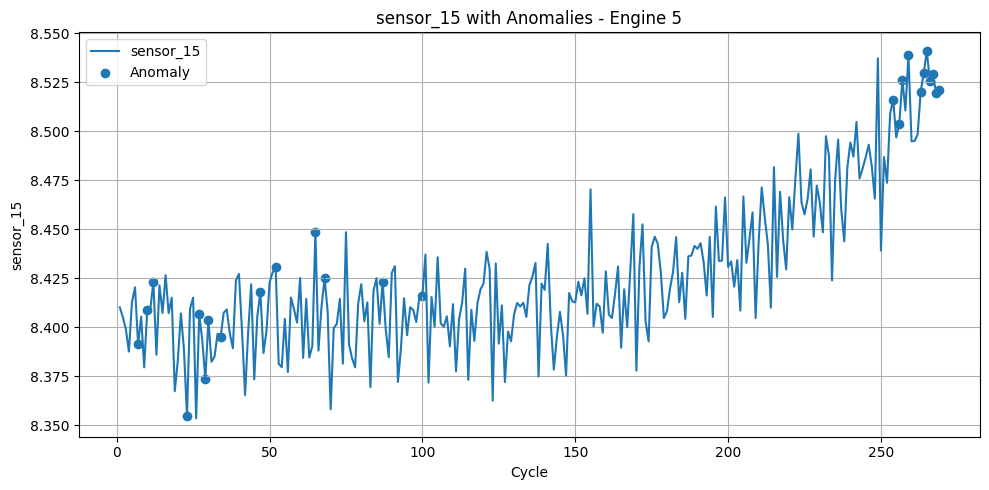

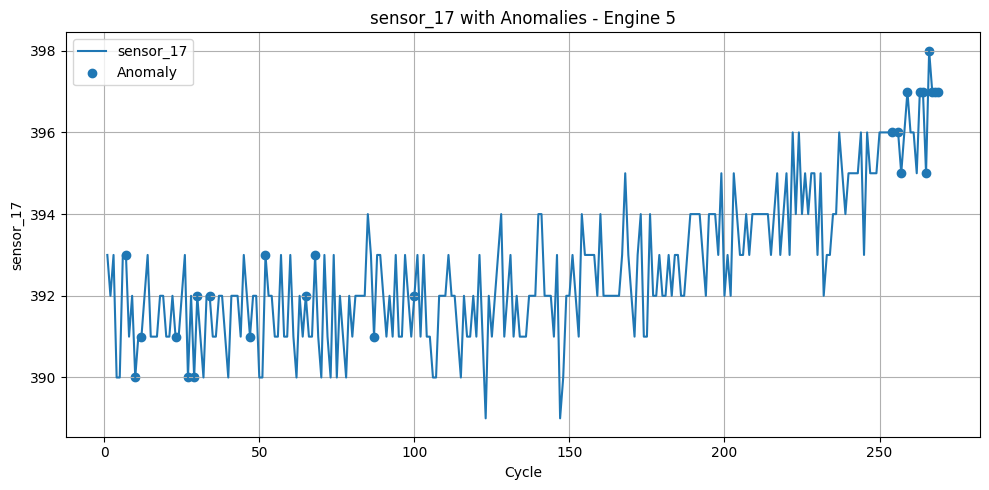

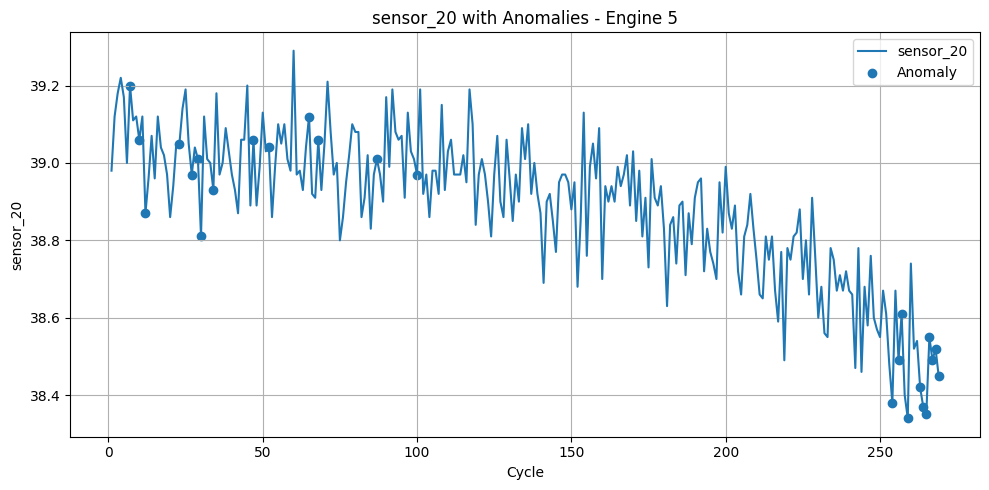

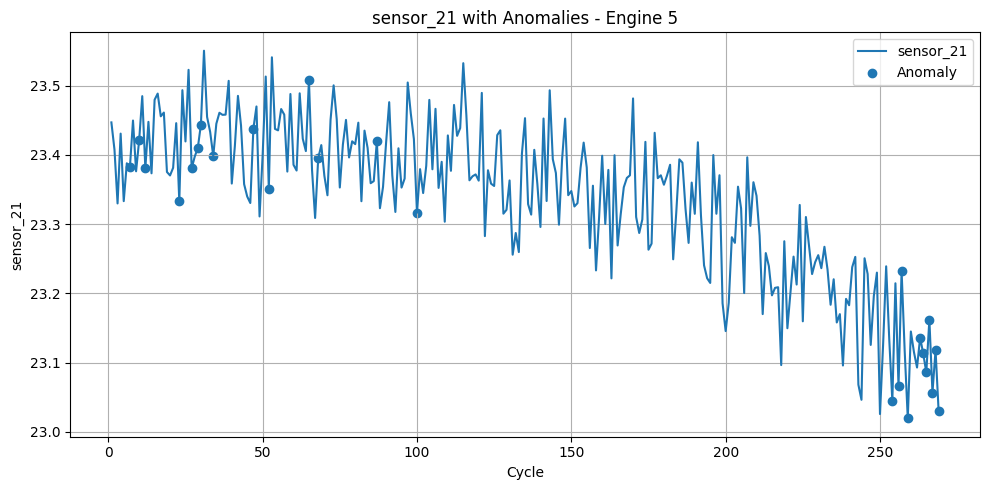

In [ ]:
import matplotlib.pyplot as plt

sensor_features = [
    col for col in df_clean.columns
    if col.startswith("sensor_")
]

engine_data = df_clean[df_clean["unit_id"] == top_engine]
anomaly_data = engine_data[engine_data["anomaly"] == -1]

for sensor in sensor_features:
    plt.figure(figsize=(10, 5))

    plt.plot(
        engine_data["cycle"],
        engine_data[sensor],
        label=sensor
    )

    plt.scatter(
        anomaly_data["cycle"],
        anomaly_data[sensor],
        label="Anomaly"
    )

    plt.xlabel("Cycle")
    plt.ylabel(sensor)
    plt.title(f"{sensor} with Anomalies - Engine {top_engine}")

    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.show()

In [ ]:
engine_stream = df_clean[df_clean["unit_id"] == top_engine]

for _, row in engine_stream.iterrows():
    print(
        "Engine:", row["unit_id"],
        "| Cycle:", row["cycle"],
        "| Status:", "Anomaly" if row["anomaly"] == -1 else "Normal"
    )

Engine: 5.0 | Cycle: 1.0 | Status: Normal
Engine: 5.0 | Cycle: 2.0 | Status: Normal
Engine: 5.0 | Cycle: 3.0 | Status: Normal
Engine: 5.0 | Cycle: 4.0 | Status: Normal
Engine: 5.0 | Cycle: 5.0 | Status: Normal
Engine: 5.0 | Cycle: 6.0 | Status: Normal
Engine: 5.0 | Cycle: 7.0 | Status: Anomaly
Engine: 5.0 | Cycle: 8.0 | Status: Normal
Engine: 5.0 | Cycle: 9.0 | Status: Normal
Engine: 5.0 | Cycle: 10.0 | Status: Anomaly
Engine: 5.0 | Cycle: 11.0 | Status: Normal
Engine: 5.0 | Cycle: 12.0 | Status: Anomaly
Engine: 5.0 | Cycle: 13.0 | Status: Normal
Engine: 5.0 | Cycle: 14.0 | Status: Normal
Engine: 5.0 | Cycle: 15.0 | Status: Normal
Engine: 5.0 | Cycle: 16.0 | Status: Normal
Engine: 5.0 | Cycle: 17.0 | Status: Normal
Engine: 5.0 | Cycle: 18.0 | Status: Normal
Engine: 5.0 | Cycle: 19.0 | Status: Normal
Engine: 5.0 | Cycle: 20.0 | Status: Normal
Engine: 5.0 | Cycle: 21.0 | Status: Normal
Engine: 5.0 | Cycle: 22.0 | Status: Normal
Engine: 5.0 | Cycle: 23.0 | Status: Anomaly
Engine: 5.0 | Cy

## 10. Real-Time Monitoring Simulation

In [ ]:
for _, row in engine_stream.iterrows():

    if row["anomaly"] == -1:
        print("🚨 ANOMALY DETECTED")
    else:
        print("Normal")

    print("Engine:", row["unit_id"])
    print("Cycle:", row["cycle"])
    print("-" * 30)

Normal
Engine: 5.0
Cycle: 1.0
------------------------------
Normal
Engine: 5.0
Cycle: 2.0
------------------------------
Normal
Engine: 5.0
Cycle: 3.0
------------------------------
Normal
Engine: 5.0
Cycle: 4.0
------------------------------
Normal
Engine: 5.0
Cycle: 5.0
------------------------------
Normal
Engine: 5.0
Cycle: 6.0
------------------------------
🚨 ANOMALY DETECTED
Engine: 5.0
Cycle: 7.0
------------------------------
Normal
Engine: 5.0
Cycle: 8.0
------------------------------
Normal
Engine: 5.0
Cycle: 9.0
------------------------------
🚨 ANOMALY DETECTED
Engine: 5.0
Cycle: 10.0
------------------------------
Normal
Engine: 5.0
Cycle: 11.0
------------------------------
🚨 ANOMALY DETECTED
Engine: 5.0
Cycle: 12.0
------------------------------
Normal
Engine: 5.0
Cycle: 13.0
------------------------------
Normal
Engine: 5.0
Cycle: 14.0
------------------------------
Normal
Engine: 5.0
Cycle: 15.0
------------------------------
Normal
Engine: 5.0
Cycle: 16.0
------------

## 11. Monitoring Results

In [ ]:
total_cycles = len(engine_stream)

total_anomalies = (engine_stream["anomaly"] == -1).sum()

anomaly_percentage = (total_anomalies / total_cycles) * 100

print("===== ENGINE MONITORING SUMMARY =====")
print("Engine:", top_engine)
print("Total Cycles:", total_cycles)
print("Total Anomalies:", total_anomalies)
print("Anomaly Percentage:", round(anomaly_percentage, 2), "%")

if total_anomalies > 0:
    print("Status: 🚨 Anomalies Detected")
else:
    print("Status: ✅ Normal")

===== ENGINE MONITORING SUMMARY =====
Engine: 5
Total Cycles: 269
Total Anomalies: 25
Anomaly Percentage: 9.29 %
Status: 🚨 Anomalies Detected


In [ ]:
print("=" * 45)
print("          ENGINE ANOMALY MONITORING")
print("=" * 45)

print("Engine ID:", top_engine)
print("Total Cycles:", total_cycles)
print("Total Anomalies:", total_anomalies)
print("Anomaly Percentage:", round(anomaly_percentage, 2), "%")

if total_anomalies > 0:
    print("Current Status: 🚨 ANOMALIES DETECTED")
else:
    print("Current Status: ✅ NORMAL")

print("=" * 45)

          ENGINE ANOMALY MONITORING
Engine ID: 5
Total Cycles: 269
Total Anomalies: 25
Anomaly Percentage: 9.29 %
Current Status: 🚨 ANOMALIES DETECTED


In [ ]:
anomaly_by_engine = anomalies["unit_id"].value_counts()

print("Anomalies by Engine:")
print(anomaly_by_engine)

average_anomalies = anomaly_by_engine.mean()

print("\nAverage anomalies per engine:", round(average_anomalies, 2))

Anomalies by Engine:
unit_id
5     25
2     23
75    22
95    21
83    20
      ..
20     4
70     4
85     4
93     4
98     3
Name: count, Length: 100, dtype: int64

Average anomalies per engine: 10.32


In [ ]:
anomaly_by_cycle = anomalies["cycle"].value_counts().sort_index()

print("Anomalies by Cycle:")
print(anomaly_by_cycle)

Anomalies by Cycle:
cycle
1      4
2      5
3      4
4      3
5      2
      ..
358    1
359    1
360    1
361    1
362    1
Name: count, Length: 288, dtype: int64


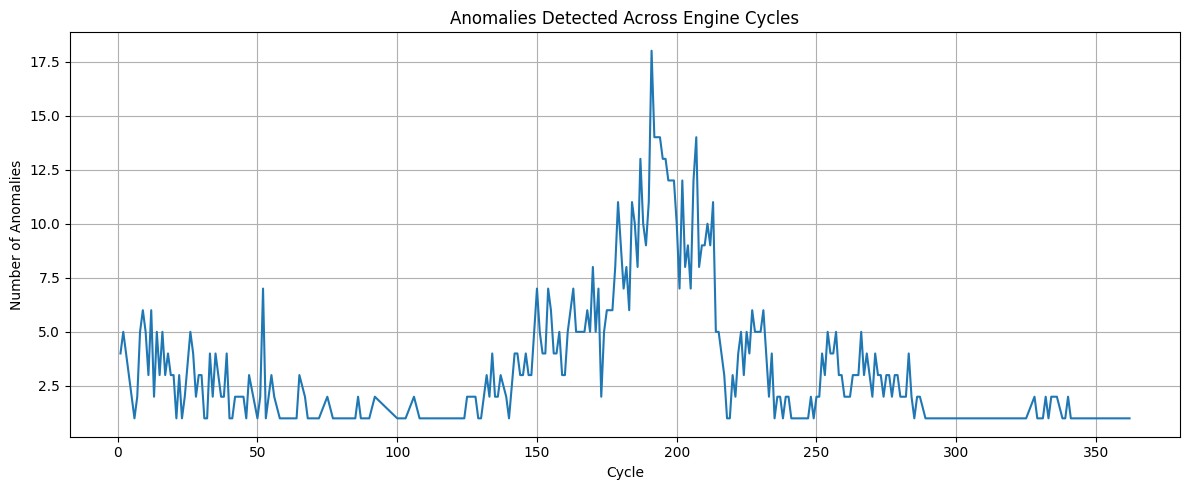

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

anomaly_by_cycle.plot(kind="line")

plt.xlabel("Cycle")
plt.ylabel("Number of Anomalies")
plt.title("Anomalies Detected Across Engine Cycles")

plt.grid(True)
plt.tight_layout()

plt.show()

## 12. Final Model Results

In [ ]:
total_observations = len(df_clean)

normal_observations = (df_clean["anomaly"] == 1).sum()
anomalous_observations = (df_clean["anomaly"] == -1).sum()

anomaly_rate = (anomalous_observations / total_observations) * 100

print("=" * 45)
print("        ISOLATION FOREST RESULTS")
print("=" * 45)

print("Total Observations:", total_observations)
print("Normal Observations:", normal_observations)
print("Anomalous Observations:", anomalous_observations)
print("Anomaly Rate:", round(anomaly_rate, 2), "%")

print("=" * 45)

        ISOLATION FOREST RESULTS
Total Observations: 20631
Normal Observations: 19599
Anomalous Observations: 1032
Anomaly Rate: 5.0 %


## 12.1 Final Model Results

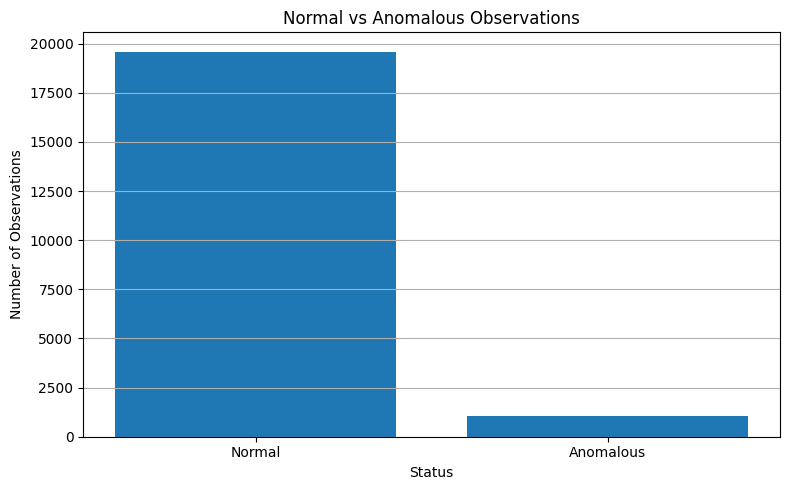

In [ ]:
import matplotlib.pyplot as plt

status_counts = [
    normal_observations,
    anomalous_observations
]

status_labels = [
    "Normal",
    "Anomalous"
]

plt.figure(figsize=(8, 5))

plt.bar(status_labels, status_counts)

plt.xlabel("Status")
plt.ylabel("Number of Observations")
plt.title("Normal vs Anomalous Observations")

plt.grid(axis="y")
plt.tight_layout()

plt.show()

In [ ]:
print("=" * 50)
print("       REAL-TIME ENGINE MONITORING SYSTEM")
print("=" * 50)

print("Engine:", top_engine)
print("Total Cycles:", total_cycles)
print("Total Anomalies:", total_anomalies)
print("Anomaly Rate:", round(anomaly_percentage, 2), "%")

if total_anomalies > 0:
    print("System Status: 🚨 ANOMALIES DETECTED")
else:
    print("System Status: ✅ NORMAL")

print("=" * 50)

       REAL-TIME ENGINE MONITORING SYSTEM
Engine: 5
Total Cycles: 269
Total Anomalies: 25
Anomaly Rate: 9.29 %
System Status: 🚨 ANOMALIES DETECTED


## 13. Save Anomaly Results

In [ ]:
anomalies.to_csv("detected_anomalies.csv", index=False)

print("Anomaly results saved successfully.")

Anomaly results saved successfully.


## 14. Final Monitoring Dashboard

          REAL-TIME ENGINE MONITORING DASHBOARD
Engine ID: 5
Total Cycles: 269
Total Anomalies: 25
Anomaly Rate: 9.29 %
System Status: 🚨 ANOMALIES DETECTED


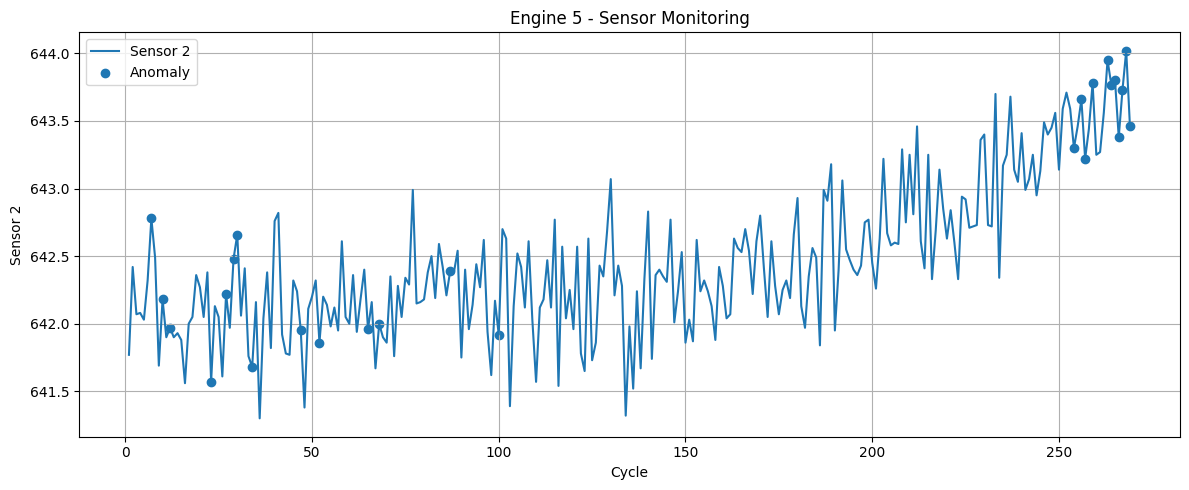

In [ ]:
import matplotlib.pyplot as plt

print("=" * 55)
print("          REAL-TIME ENGINE MONITORING DASHBOARD")
print("=" * 55)

print("Engine ID:", top_engine)
print("Total Cycles:", total_cycles)
print("Total Anomalies:", total_anomalies)
print("Anomaly Rate:", round(anomaly_percentage, 2), "%")

if total_anomalies > 0:
    print("System Status: 🚨 ANOMALIES DETECTED")
else:
    print("System Status: ✅ NORMAL")

print("=" * 55)

plt.figure(figsize=(12, 5))

plt.plot(
    engine_stream["cycle"],
    engine_stream["sensor_2"],
    label="Sensor 2"
)

anomaly_points = engine_stream[
    engine_stream["anomaly"] == -1
]

plt.scatter(
    anomaly_points["cycle"],
    anomaly_points["sensor_2"],
    label="Anomaly"
)

plt.xlabel("Cycle")
plt.ylabel("Sensor 2")
plt.title(
    f"Engine {top_engine} - Sensor Monitoring"
)

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

## 15. Final Project Results

In [ ]:
print("=" * 60)
print("              FINAL PROJECT RESULTS")
print("=" * 60)

print("Dataset observations:", total_observations)
print("Number of engines:", df_clean["unit_id"].nunique())
print("Sensors used for model:", len(sensor_features))

print("Normal observations:", normal_observations)
print("Anomalous observations:", anomalous_observations)
print("Overall anomaly rate:", round(anomaly_rate, 2), "%")

print("Engine analyzed in detail:", top_engine)
print("Anomalies in selected engine:", total_anomalies)
print("Selected engine anomaly rate:",
      round(anomaly_percentage, 2), "%")

print("=" * 60)

              FINAL PROJECT RESULTS
Dataset observations: 20631
Number of engines: 100
Sensors used for model: 15
Normal observations: 19599
Anomalous observations: 1032
Overall anomaly rate: 5.0 %
Engine analyzed in detail: 5
Anomalies in selected engine: 25
Selected engine anomaly rate: 9.29 %


## 16. Experiment 1 - Contamination Sensitivity

This experiment investigates how the Isolation Forest `contamination` parameter affects the number of observations classified as anomalous.

Different contamination values are tested while keeping the other model settings constant.

The tested values are 0.01, 0.03, 0.05, and 0.10.

This experiment is a model-sensitivity analysis. The detected anomaly percentage should not be interpreted as the actual percentage of faulty engine observations because the dataset does not provide explicit anomaly labels.

===== EXPERIMENT 1: CONTAMINATION SENSITIVITY =====
   Contamination  Anomalies  Anomaly Percentage
0           0.01        207                 1.0
1           0.03        619                 3.0
2           0.05       1032                 5.0
3           0.10       2063                10.0


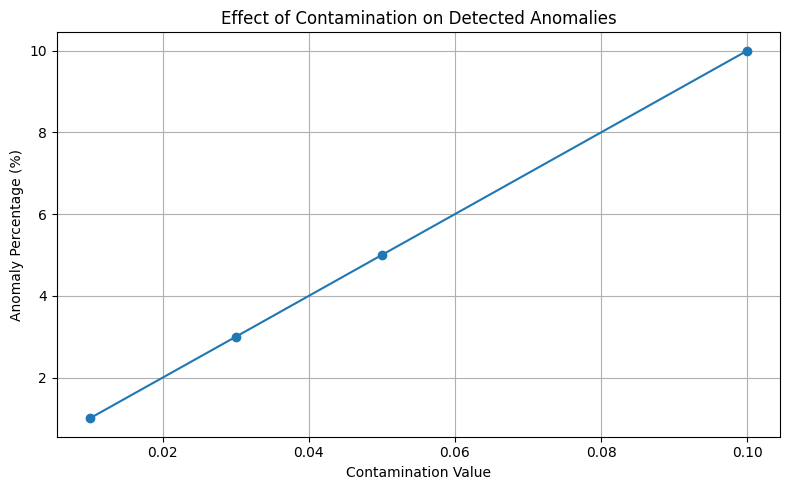

In [ ]:
from sklearn.ensemble import IsolationForest
import pandas as pd
import matplotlib.pyplot as plt

contamination_values = [0.01, 0.03, 0.05, 0.10]

contamination_results = []

for contamination in contamination_values:

    experiment_model = IsolationForest(
        n_estimators=100,
        contamination=contamination,
        random_state=42
    )

    experiment_model.fit(X)

    experiment_predictions = experiment_model.predict(X)

    anomaly_count = (experiment_predictions == -1).sum()
    anomaly_percentage = (anomaly_count / len(X)) * 100

    contamination_results.append({
        "Contamination": contamination,
        "Anomalies": anomaly_count,
        "Anomaly Percentage": anomaly_percentage
    })

contamination_results = pd.DataFrame(contamination_results)

print("===== EXPERIMENT 1: CONTAMINATION SENSITIVITY =====")
print(contamination_results.round(2))

plt.figure(figsize=(8, 5))

plt.plot(
    contamination_results["Contamination"],
    contamination_results["Anomaly Percentage"],
    marker="o"
)

plt.xlabel("Contamination Value")
plt.ylabel("Anomaly Percentage (%)")
plt.title("Effect of Contamination on Detected Anomalies")

plt.grid(True)
plt.tight_layout()

plt.show()

## 17. Experiment 2 - Number of Estimators Sensitivity

This experiment investigates how the number of trees in the Isolation Forest affects the detected anomalies.

Different values of `n_estimators` are tested while keeping the contamination value fixed at 0.05.

The tested values are 50, 100, 200, and 300.

This experiment evaluates whether changing the number of trees produces noticeable changes in the anomaly detection results.

===== EXPERIMENT 2: NUMBER OF ESTIMATORS SENSITIVITY =====
   Number of Estimators  Anomalies  Anomaly Percentage
0                    50       1032                 5.0
1                   100       1032                 5.0
2                   200       1032                 5.0
3                   300       1032                 5.0


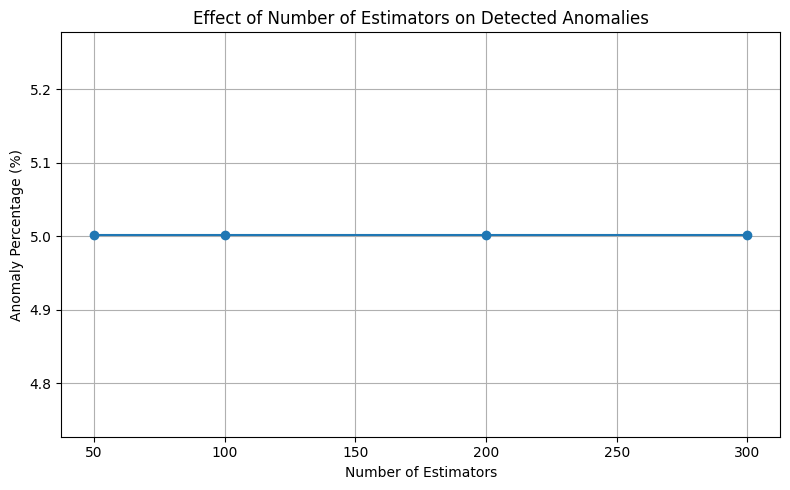

In [ ]:
from sklearn.ensemble import IsolationForest
import pandas as pd
import matplotlib.pyplot as plt

estimator_values = [50, 100, 200, 300]

estimator_results = []

for n_estimators in estimator_values:

    estimator_model = IsolationForest(
        n_estimators=n_estimators,
        contamination=0.05,
        random_state=42
    )

    estimator_model.fit(X)

    estimator_predictions = estimator_model.predict(X)

    anomaly_count = (estimator_predictions == -1).sum()
    anomaly_percentage = (anomaly_count / len(X)) * 100

    estimator_results.append({
        "Number of Estimators": n_estimators,
        "Anomalies": anomaly_count,
        "Anomaly Percentage": anomaly_percentage
    })

estimator_results = pd.DataFrame(estimator_results)

print("===== EXPERIMENT 2: NUMBER OF ESTIMATORS SENSITIVITY =====")
print(estimator_results.round(2))

plt.figure(figsize=(8, 5))

plt.plot(
    estimator_results["Number of Estimators"],
    estimator_results["Anomaly Percentage"],
    marker="o"
)

plt.xlabel("Number of Estimators")
plt.ylabel("Anomaly Percentage (%)")
plt.title("Effect of Number of Estimators on Detected Anomalies")

plt.grid(True)
plt.tight_layout()

plt.show()

## 18. Experiment 3 - Anomaly Distribution Analysis

This experiment analyzes how the anomalies detected by the main Isolation Forest model are distributed across the engines.

The number of anomalous observations is calculated for each engine.

The experiment also examines the distribution of anomaly counts across engines and identifies the engines with the highest numbers of detected anomalies.

This analysis helps us understand whether the detected anomalies are distributed relatively evenly across the dataset or concentrated in particular engines.

===== EXPERIMENT 3: ANOMALY DISTRIBUTION =====

Anomalies per Engine:
1       8
2      23
3       9
4      11
5      25
       ..
96     11
97      9
98      3
99      7
100    10
Length: 100, dtype: int64

Summary:
Number of engines: 100
Engines with anomalies: 100
Engines without anomalies: 0
Maximum anomalies in one engine: 25
Minimum anomalies in one engine: 3
Average anomalies per engine: 10.32

Top 10 Engines by Anomaly Count:
5     25
2     23
75    22
95    21
83    20
78    20
33    20
61    19
9     19
73    18
dtype: int64


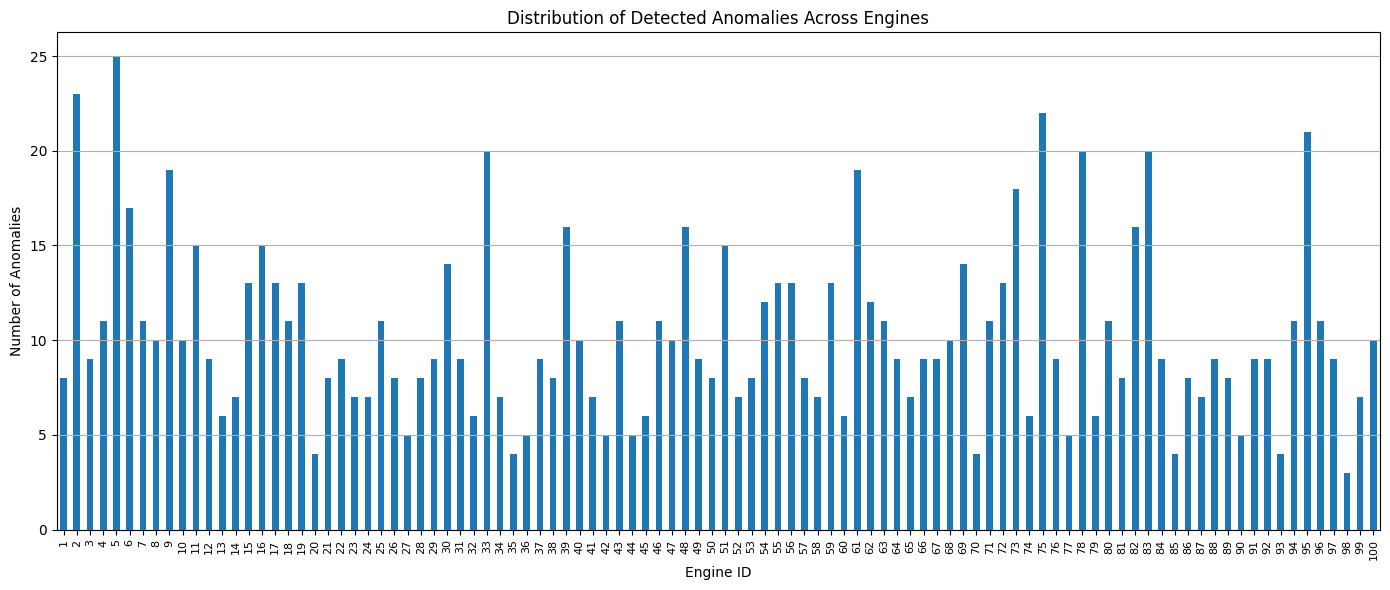

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Use the anomalies detected by the main model
experiment3_anomalies = df_clean[df_clean["anomaly"] == -1]

# Count anomalies for each engine
anomaly_distribution = (
    experiment3_anomalies["unit_id"]
    .value_counts()
    .sort_index()
)

# Include engines with zero anomalies
all_engines = pd.Series(
    0,
    index=sorted(df_clean["unit_id"].unique())
)

all_engines.update(anomaly_distribution)

anomaly_distribution = all_engines.astype(int)

print("===== EXPERIMENT 3: ANOMALY DISTRIBUTION =====")

print("\nAnomalies per Engine:")
print(anomaly_distribution)

print("\nSummary:")
print("Number of engines:", len(anomaly_distribution))
print("Engines with anomalies:", (anomaly_distribution > 0).sum())
print("Engines without anomalies:", (anomaly_distribution == 0).sum())
print("Maximum anomalies in one engine:", anomaly_distribution.max())
print("Minimum anomalies in one engine:", anomaly_distribution.min())
print("Average anomalies per engine:",
      round(anomaly_distribution.mean(), 2))

# Show top 10 engines
top_10_engines = anomaly_distribution.sort_values(
    ascending=False
).head(10)

print("\nTop 10 Engines by Anomaly Count:")
print(top_10_engines)

# Plot anomaly distribution
plt.figure(figsize=(14, 6))

anomaly_distribution.plot(kind="bar")

plt.xlabel("Engine ID")
plt.ylabel("Number of Anomalies")
plt.title("Distribution of Detected Anomalies Across Engines")

plt.xticks(rotation=90, fontsize=8)

plt.grid(axis="y")
plt.tight_layout()

plt.show()

## 19. Experiment 4 - Detailed Investigation of Selected Engine

This experiment investigates the engine with the highest number of detected anomalies.

Based on Experiment 3, Engine 5 has the highest anomaly count with 25 detected anomalous observations.

The sensor measurements of Engine 5 are examined across its operating cycles, with anomalous observations highlighted.

The purpose is to investigate the sensor patterns associated with model-detected anomalies. These anomalies represent unusual combined sensor patterns and should not be interpreted as confirmed physical engine failures.

===== EXPERIMENT 4: ENGINE 5 INVESTIGATION =====
Engine: 5
Total cycles: 269
Normal observations: 244
Anomalous observations: 25

Anomalous cycles:
 unit_id  cycle  anomaly
       5      7       -1
       5     10       -1
       5     12       -1
       5     23       -1
       5     27       -1
       5     29       -1
       5     30       -1
       5     34       -1
       5     47       -1
       5     52       -1
       5     65       -1
       5     68       -1
       5     87       -1
       5    100       -1
       5    254       -1
       5    256       -1
       5    257       -1
       5    259       -1
       5    263       -1
       5    264       -1
       5    265       -1
       5    266       -1
       5    267       -1
       5    268       -1
       5    269       -1


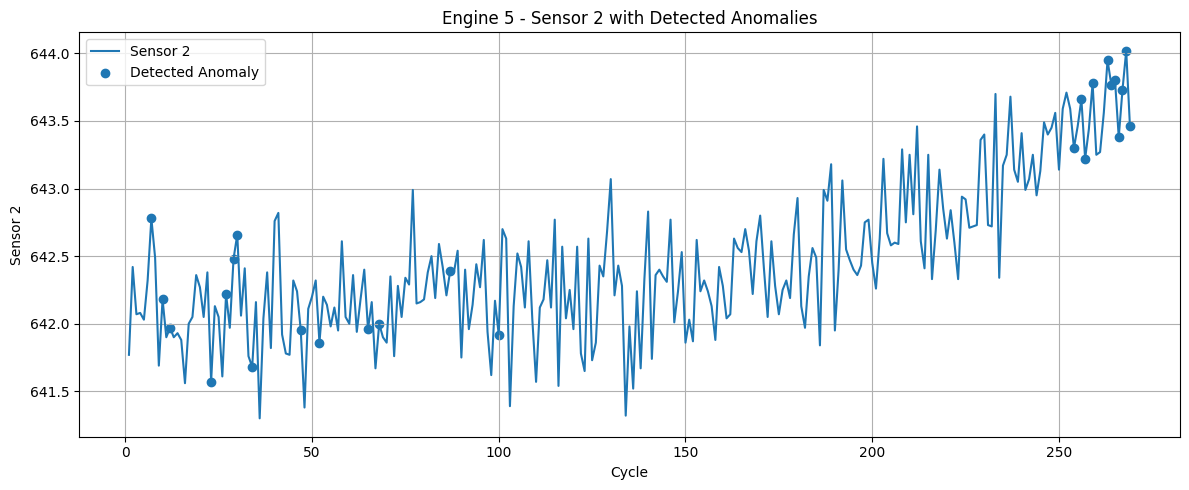

In [ ]:
import matplotlib.pyplot as plt

# Select Engine 5 identified in Experiment 3
selected_engine = 5

engine5_data = df_clean[
    df_clean["unit_id"] == selected_engine
].copy()

# Separate normal and anomalous observations
engine5_anomalies = engine5_data[
    engine5_data["anomaly"] == -1
]

engine5_normal = engine5_data[
    engine5_data["anomaly"] == 1
]

print("===== EXPERIMENT 4: ENGINE 5 INVESTIGATION =====")

print("Engine:", selected_engine)
print("Total cycles:", len(engine5_data))
print("Normal observations:", len(engine5_normal))
print("Anomalous observations:", len(engine5_anomalies))

print("\nAnomalous cycles:")
print(
    engine5_anomalies[
        ["unit_id", "cycle", "anomaly"]
    ].to_string(index=False)
)

# Plot Sensor 2 with anomalies highlighted
plt.figure(figsize=(12, 5))

plt.plot(
    engine5_data["cycle"],
    engine5_data["sensor_2"],
    label="Sensor 2"
)

plt.scatter(
    engine5_anomalies["cycle"],
    engine5_anomalies["sensor_2"],
    label="Detected Anomaly"
)

plt.xlabel("Cycle")
plt.ylabel("Sensor 2")
plt.title("Engine 5 - Sensor 2 with Detected Anomalies")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

## 20. Results and Discussion



### Dataset and Feature Preparation

The FD001 dataset contains 20,631 observations from 100 engines. The original dataset contains 21 sensor measurement columns. Six sensors were constant in this dataset and were removed, leaving 15 variable sensor features for the anomaly-detection model.

### Isolation Forest Results

The Isolation Forest model classified 19,599 observations as normal and 1,032 observations as anomalous. The resulting anomaly rate was approximately 5%.

The anomaly rate should be interpreted in relation to the model configuration because the Isolation Forest was trained with a contamination value of 0.05. Therefore, the detected anomalies represent observations that the model identified as unusual under the selected configuration rather than confirmed physical failures.

### Experiment 1: Contamination Sensitivity

The contamination sensitivity experiment tested values of 0.01, 0.03, 0.05, and 0.10.

The detected anomaly counts were 207, 619, 1,032, and 2,063 respectively. The corresponding anomaly percentages were approximately 1%, 3%, 5%, and 10%.

The results show that the number of detected anomalies increases as the contamination value increases. This demonstrates that the contamination parameter has a direct effect on the number of observations classified as anomalous.

### Experiment 2: Number of Estimators Sensitivity

The number of estimators experiment tested 50, 100, 200, and 300 trees while keeping contamination fixed at 0.05.

For all four tested values, the model detected 1,032 anomalies, corresponding to approximately 5% of the observations.

This indicates that, for the tested settings, changing the number of trees did not change the overall number of detected anomalies.

### Experiment 3: Anomaly Distribution Analysis

The anomaly distribution experiment examined the number of detected anomalies across all 100 engines.

All 100 engines contained at least one model-detected anomaly. The number of anomalies per engine ranged from 3 to 25, with an average of 10.32 anomalies per engine.

Engine 5 had the highest number of detected anomalies, with 25 observations classified as anomalous. This engine was therefore selected for the detailed investigation in Experiment 4.

The result indicates where the model identified more unusual observations, but the anomaly count should not be interpreted as a measure of actual engine failure.

### Experiment 4: Detailed Investigation of Engine 5

Engine 5 contains 269 operating cycles. The Isolation Forest classified 244 observations as normal and 25 observations as anomalous.

The detected anomalous cycles were examined using the sensor measurements. The Sensor 2 visualization highlights the locations of the model-detected anomalies across the engine's operating history.

Several anomalous observations occur during the later cycles of Engine 5. These observations indicate unusual combined sensor patterns according to the trained model. They should not be interpreted as confirmed physical engine failures.

### Real-Time Monitoring Simulation

The project simulates real-time monitoring by processing historical C-MAPSS observations sequentially, one observation at a time. Each observation is assigned a normal or anomaly status using the trained Isolation Forest model.

This provides a prototype of a sensor-monitoring system without claiming to receive live aircraft sensor data.

### Overall Interpretation

The experiments demonstrate that the Isolation Forest model can identify unusual sensor patterns in the FD001 dataset.

The contamination experiment shows that the selected contamination value strongly affects the number of detected anomalies, while the estimator experiment showed stable anomaly counts across the tested number of trees.

The anomaly distribution analysis and Engine 5 investigation provide additional information about where the model detected unusual observations.

Overall, the detected anomalies should be treated as alerts for further investigation rather than as proof of specific physical faults.

## 21. Limitations

### Limitations

1. The project uses historical C-MAPSS FD001 data, so the monitoring system is a simulation of real-time sensor streaming rather than a connection to live aircraft sensors.

2. The Isolation Forest model is unsupervised and the dataset used in this project does not provide explicit anomaly labels for each observation. Therefore, conventional supervised metrics such as accuracy, precision, and recall cannot be directly calculated from the available data.

3. The contamination parameter was set to 0.05. This is a model configuration that influences the expected proportion of observations classified as anomalies and should not be interpreted as the actual percentage of faulty engine observations.

4. A detected anomaly represents an unusual combined sensor pattern. It does not identify the exact physical cause of the unusual behavior or confirm that an engine has physically failed.

5. The current monitoring system focuses on sensor-pattern anomalies and does not provide a specific fault diagnosis or remaining-useful-life prediction.

6. The project uses one C-MAPSS experimental subset, FD001. Other C-MAPSS subsets contain different operating-condition and fault-mode configurations and could be used for additional experimentation.

## 22. Project Architecture and Workflow



**C-MAPSS FD001 Historical Data**
→ **Data Loading**
→ **Dataset Understanding**
→ **Sensor Statistics**
→ **Remove Constant Sensors**
→ **Select 15 Sensor Features**
→ **Standardize Sensor Data**
→ **Train Isolation Forest**
→ **Detect Anomalies**
→ **Analyze Anomalies by Engine and Cycle**
→ **Sequential Sensor Streaming Simulation**
→ **Monitoring Dashboard**
→ **Anomaly Alerts and Results**

## 23. Conclusion

The project developed a sensor anomaly-detection and monitoring prototype using NASA C-MAPSS FD001 historical engine data.

The sensor measurements were analyzed, constant sensors were removed, and the remaining sensor features were standardized before training an Isolation Forest model.

The trained model classified observations as normal or anomalous based on how unusual their combined sensor patterns were.

Four experiments were conducted to investigate the model results. The contamination sensitivity experiment showed that the contamination parameter directly affects the number of detected anomalies. The number of estimators experiment showed stable anomaly counts across the tested values. The anomaly distribution experiment examined how detected anomalies were distributed across the engines, and Engine 5 was selected for detailed investigation because it had the highest number of model-detected anomalies.

Historical observations were then processed sequentially to simulate real-time monitoring, and anomaly results were visualized for further analysis.

The detected anomalies indicate unusual sensor patterns and should not be interpreted directly as confirmed physical engine failures.